In [1]:
# %pip install torch
# %pip install numpy pandas matplotlib seaborn scikit-learn tensorflow pillow
# %pip install kagglehub

In [2]:
import kagglehub
from pathlib import Path

# Download latest version
path = kagglehub.dataset_download("ashfakyeafi/road-vehicle-images-dataset")
DATASET_DIR = Path(path)/"trafic_data"
for split in ["train", "valid"]:
    images_dir = DATASET_DIR / split / "images"
    labels_dir = DATASET_DIR / split / "labels"

    print(f"\n{split.upper()}")
    print("Images directory exists:", images_dir.exists())
    print("Labels directory exists:", labels_dir.exists())

c:\Users\laaou\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



TRAIN
Images directory exists: True
Labels directory exists: True

VALID
Images directory exists: True
Labels directory exists: True


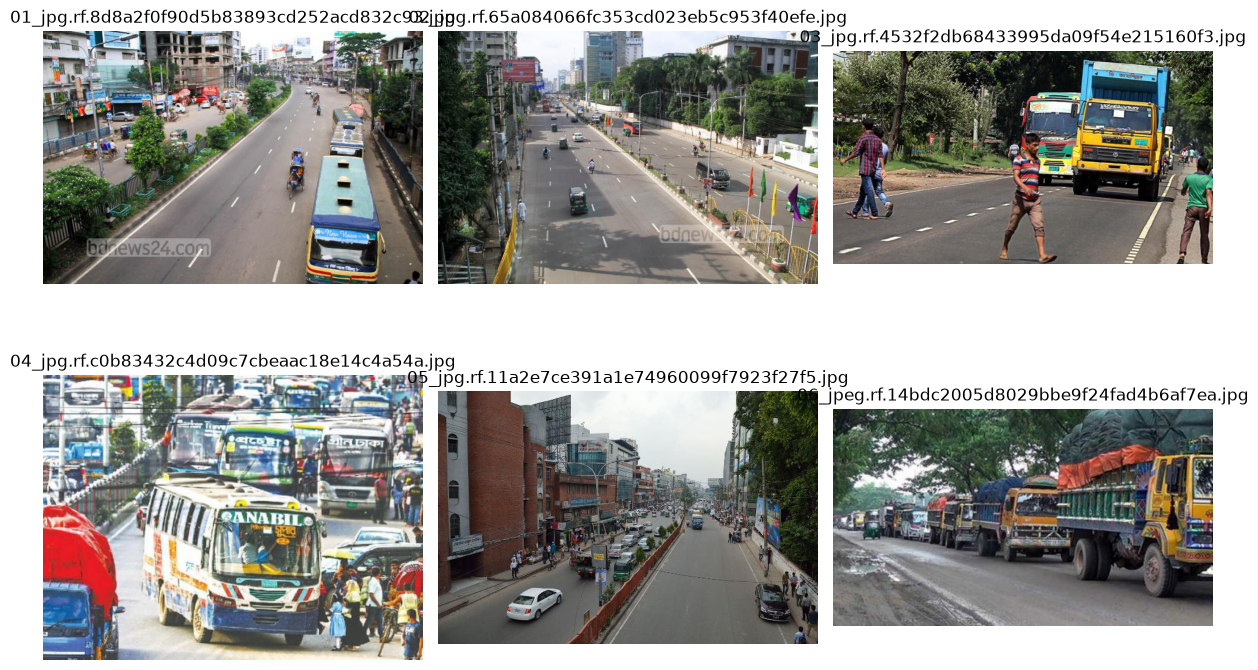

In [3]:

from PIL import Image
import matplotlib.pyplot as plt

images_dir = DATASET_DIR / "train" / "images"
image_files = []

for ext in ["*.jpeg", "*.jpg", "*.png", "*.webp"]:
    image_files.extend(images_dir.glob(ext))

plt.figure(figsize=(12, 8))

for i, image_path in enumerate(image_files[:6]):
    with Image.open(image_path) as img:
        plt.subplot(2, 3, i + 1)
        plt.imshow(img.convert("RGB"))
        plt.title(image_path.name)
        plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
import yaml

yaml_path = DATASET_DIR / "data_1.yaml"

with open(yaml_path, "r") as file:
    data = yaml.safe_load(file)


class_names = data["names"]
num_classes = data["nc"]

class_ids = set(range(num_classes))
print(data)
print("Classes:", data.get("names"))
print("Number of classes:", data.get("nc"))
print("Expected class IDs:", class_ids)


{'train': '../train/images', 'val': '../valid/images', 'nc': 21, 'names': ['ambulance', 'army vehicle', 'auto rickshaw', 'bicycle', 'bus', 'car', 'garbagevan', 'human hauler', 'minibus', 'minivan', 'motorbike', 'pickup', 'policecar', 'rickshaw', 'scooter', 'suv', 'taxi', 'three wheelers -CNG-', 'truck', 'van', 'wheelbarrow']}
Classes: ['ambulance', 'army vehicle', 'auto rickshaw', 'bicycle', 'bus', 'car', 'garbagevan', 'human hauler', 'minibus', 'minivan', 'motorbike', 'pickup', 'policecar', 'rickshaw', 'scooter', 'suv', 'taxi', 'three wheelers -CNG-', 'truck', 'van', 'wheelbarrow']
Number of classes: 21
Expected class IDs: {0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20}


In [5]:

# Get the valid class IDs
if isinstance(class_names, dict):
    valid_class_ids = set(map(int, class_names.keys()))
else:
    valid_class_ids = set(range(len(class_names)))

print("Class names:", class_names)
print("Number of classes:", num_classes)
print("Valid class IDs:", valid_class_ids)

Class names: ['ambulance', 'army vehicle', 'auto rickshaw', 'bicycle', 'bus', 'car', 'garbagevan', 'human hauler', 'minibus', 'minivan', 'motorbike', 'pickup', 'policecar', 'rickshaw', 'scooter', 'suv', 'taxi', 'three wheelers -CNG-', 'truck', 'van', 'wheelbarrow']
Number of classes: 21
Valid class IDs: {0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20}


In [6]:

def check_annotations(name, valid_class_ids):
    labels_dir = DATASET_DIR / name / "labels"
    images_dir = DATASET_DIR / name / "images"

    valid_images = []
    invalid_images = []
    missing_labels = []
    empty_labels = []

    for ext in ["*.jpeg", "*.jpg", "*.png", "*.webp"]:
        for img_path in images_dir.glob(ext):
            label_path = labels_dir / f"{img_path.stem}.txt"

            # Check if the label file exists
            if not label_path.exists():
                missing_labels.append(img_path)
                continue

            # Check if the label file is empty
            lines = label_path.read_text().splitlines()

            if len(label_path.read_text().strip()) == 0:
                empty_labels.append(img_path)
                continue

            is_valid = True

            for line in lines:
                values = line.split()

                if not values:
                    continue

                # Each annotation must contain 5 values
                if len(values) != 5:
                    is_valid = False
                    break

                try:
                    class_id = int(values[0])
                    x, y, width, height = map(float, values[1:])
                except ValueError:
                    is_valid = False
                    break

                # Check class ID
                if class_id not in valid_class_ids:
                    is_valid = False
                    break

                # Check normalized coordinates
                if not (0 <= x <= 1 and 0 <= y <= 1
                        and 0 <= width <= 1 and 0 <= height <= 1):
                    is_valid = False
                    break

                # Width and height must be positive
                if width == 0 or height == 0:
                    is_valid = False
                    break

            if is_valid:
                valid_images.append(img_path)
            else:
                invalid_images.append(img_path)

    # print("Valid images:", len(valid_images))
    # print("Invalid annotations:", len(invalid_images))
    # print("Missing labels:", len(missing_labels))
    # print("Empty labels:", len(empty_labels))

    return valid_images, invalid_images, missing_labels, empty_labels


In [11]:
train_images = check_annotations("train", valid_class_ids)[0]
valid_images = check_annotations("valid", valid_class_ids)[0]

print(len(train_images))
print(len(valid_images))


2702
298


In [8]:
corrupted_images = []
for image_files in [train_images,valid_images]:
    for img_path in image_files:
        try:
            with Image.open(img_path) as img:
                img.verify()
        except Exception:
            corrupted_images.append(img_path)

print("Corrupted images:", len(corrupted_images))

Corrupted images: 0


In [12]:
from sklearn.model_selection import train_test_split

# Séparer les images d'entraînement et de test
train_images, test_images = train_test_split(
    train_images,
    test_size=405,
    random_state=42,
    shuffle=True
)

print("Train :", len(train_images))
print("Validation :", len(valid_images))
print("Test :", len(test_images))

Train : 2297
Validation : 298
Test : 405


In [13]:
print(train_images[0])
print(type(train_images[0]))

C:\Users\laaou\.cache\kagglehub\datasets\ashfakyeafi\road-vehicle-images-dataset\versions\2\trafic_data\train\images\Navid_130_jpg.rf.b784d8d1b278bac62b6865bb515a275b.jpg
<class 'pathlib.WindowsPath'>


In [15]:
from pathlib import Path

# Dossier de destination
OUTPUT_DIR = Path(
    r"C:\Users\laaou\OneDrive\Desktop\projects\Vehix AI\road_vehicle_final"
)

# Créer l'arborescence
for split in ["train", "valid", "test"]:
    (OUTPUT_DIR / split / "images").mkdir(parents=True, exist_ok=True)
    (OUTPUT_DIR / split / "labels").mkdir(parents=True, exist_ok=True)

print("Dossiers créés dans :", OUTPUT_DIR)

Dossiers créés dans : C:\Users\laaou\OneDrive\Desktop\projects\Vehix AI\road_vehicle_final


In [16]:
import shutil

def copy_images_and_labels(image_list, source_split, destination_split):
    for image_path in image_list:
        image_path = Path(image_path)

        # Chemin de l'annotation YOLO correspondante
        label_path = (
            DATASET_DIR / source_split / "labels"
            / f"{image_path.stem}.txt"
        )

        # Destination des fichiers
        new_image_path = OUTPUT_DIR / destination_split / "images" / image_path.name
        new_label_path = OUTPUT_DIR / destination_split / "labels" / label_path.name

        # Copier l'image et son annotation
        shutil.copy2(image_path, new_image_path)
        shutil.copy2(label_path, new_label_path)

In [17]:
# Copier les images d'entraînement restantes
copy_images_and_labels(train_images, "train", "train")

# Copier les images de validation
copy_images_and_labels(valid_images, "valid", "valid")

# Copier les images de test sélectionnées depuis train
copy_images_and_labels(test_images, "train", "test")

print("Copie terminée.")

Copie terminée.


In [18]:
for split in ["train", "valid", "test"]:

    images_dir = OUTPUT_DIR / split / "images"
    labels_dir = OUTPUT_DIR / split / "labels"

    # Compter les images et les annotations
    image_files = list(images_dir.glob("*"))
    label_files = list(labels_dir.glob("*.txt"))

    print(f"\n{split.upper()}")
    print("Images :", len(image_files))
    print("Annotations :", len(label_files))


TRAIN
Images : 2297
Annotations : 2297

VALID
Images : 298
Annotations : 298

TEST
Images : 405
Annotations : 405


In [19]:
import yaml

data_config = {
    "path": str(OUTPUT_DIR),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": len(valid_class_ids),
    "names": valid_class_ids
}

yaml_path = OUTPUT_DIR / "data.yaml"

with open(yaml_path, "w") as file:
    yaml.dump(data_config, file, sort_keys=False)

print("data.yaml créé :", yaml_path)

data.yaml créé : C:\Users\laaou\OneDrive\Desktop\projects\Vehix AI\road_vehicle_final\data.yaml


In [22]:
import yaml

yaml_path = OUTPUT_DIR / "data.yaml"

data_config = {
    "path": str(OUTPUT_DIR),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 21,
    "names": [
        "ambulance", "army vehicle", "auto rickshaw", "bicycle",
        "bus", "car", "garbagevan", "human hauler", "minibus",
        "minivan", "motorbike", "pickup", "policecar", "rickshaw",
        "scooter", "suv", "taxi", "three wheelers -CNG-",
        "truck", "van", "wheelbarrow"
    ]
}

with open(yaml_path, "w") as file:
    yaml.dump(data_config, file, sort_keys=False)

print("Updated file:", yaml_path)

Updated file: C:\Users\laaou\OneDrive\Desktop\projects\Vehix AI\road_vehicle_final\data.yaml


In [24]:
# Récupérer les noms des images de chaque ensemble
train_names = {
    image.name for image in (OUTPUT_DIR / "train" / "images").iterdir()
}

valid_names = {
    image.name for image in (OUTPUT_DIR / "valid" / "images").iterdir()
}

test_names = {
    image.name for image in (OUTPUT_DIR / "test" / "images").iterdir()
}

# Chercher les noms communs entre les ensembles
print("Train / Validation :", len(train_names & valid_names))
print("Train / Test :", len(train_names & test_names))
print("Validation / Test :", len(valid_names & test_names))


Train / Validation : 0
Train / Test : 0
Validation / Test : 0


In [25]:
import hashlib

def get_image_hash(image_path):
    md5 = hashlib.md5()

    with open(image_path, "rb") as file:
        for chunk in iter(lambda: file.read(4096), b""):
            md5.update(chunk)

    return md5.hexdigest()


split_hashes = {}

for split in ["train", "valid", "test"]:
    images_dir = OUTPUT_DIR / split / "images"
    hashes = {}

    for image_path in images_dir.iterdir():
        if image_path.is_file():
            image_hash = get_image_hash(image_path)
            hashes.setdefault(image_hash, []).append(image_path.name)

    split_hashes[split] = hashes


print("Train / Validation :", len(set(split_hashes["train"]) & set(split_hashes["valid"])))
print("Train / Test :", len(set(split_hashes["train"]) & set(split_hashes["test"])))
print("Validation / Test :", len(set(split_hashes["valid"]) & set(split_hashes["test"])))

Train / Validation : 0
Train / Test : 0
Validation / Test : 0
